# Sistem Basis Data Perpustakaan

## SOAL 1:

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

DB_PATH = "perpustakaan.db"


conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")
cursor = conn.cursor()

print(f"Koneksi berhasil : {DB_PATH}")

Koneksi berhasil : perpustakaan.db


In [2]:
# 1. Tabel buku
cursor.execute(
    """
    CREATE TABLE buku (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        judul TEXT NOT NULL,
        penulis TEXT NOT NULL,
        tahun INTEGER NOT NULL
    );
    """
)

# 2. Tabel anggota
cursor.execute(
    """
    CREATE TABLE anggota (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        nama TEXT NOT NULL,
        email TEXT NOT NULL UNIQUE
    );
    """
)

# 3. Tabel peminjaman
cursor.execute(
    """
    CREATE TABLE peminjaman (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        id_anggota INTEGER NOT NULL,
        id_buku INTEGER NOT NULL,
        tgl_pinjam TEXT NOT NULL,
        tgl_kembali TEXT,
        FOREIGN KEY (id_anggota) REFERENCES anggota(id)
            ON UPDATE CASCADE
            ON DELETE RESTRICT,
        FOREIGN KEY (id_buku) REFERENCES buku(id)
            ON UPDATE CASCADE
            ON DELETE RESTRICT
    );
    """
)

conn.commit()

pd.read_sql_query(
    "SELECT name AS nama_tabel FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%';",
    conn,
)

,nama_tabel
0,buku
1,anggota
2,peminjaman


### a. Menambahkan 5 Data Buku dan 3 Data Anggota

In [3]:
# data buku
data_buku = [
    ("Laskar Pelangi", "Andrea Hirata", 2005),
    ("Bumi Manusia", "Pramoedya Ananta", 1980),
    ("Negeri 5 Menara", "Ahmad Fuadi", 2009),
    ("Cantik Itu Luka", "Eka Kurniawan", 2002),
    ("Perahu Kertas", "Dewi Lestari", 2009),
]

cursor.executemany(
    "INSERT INTO buku (judul, penulis, tahun) VALUES (?, ?, ?);",
    data_buku,
)

# data anggota
data_anggota = [
    ("Rina Wijaya", "rina.wijaya@example.com"),
    ("Budi Santoso", "budi.santoso@example.com"),
    ("Siti Rahmawati", "siti.rahmawati@example.com"),
]

cursor.executemany(
    "INSERT INTO anggota (nama, email) VALUES (?, ?);",
    data_anggota,
)

conn.commit()

print("=== TABEL BUKU ===")
df_buku = pd.read_sql_query("SELECT * FROM buku ORDER BY id;", conn)
print(df_buku.to_string(index=False))

print("\n=== TABEL ANGGOTA ===")
df_anggota = pd.read_sql_query("SELECT * FROM anggota ORDER BY id;", conn)
print(df_anggota.to_string(index=False))

=== TABEL BUKU ===
 id           judul          penulis  tahun
  1  Laskar Pelangi    Andrea Hirata   2005
  2    Bumi Manusia Pramoedya Ananta   1980
  3 Negeri 5 Menara      Ahmad Fuadi   2009
  4 Cantik Itu Luka    Eka Kurniawan   2002
  5   Perahu Kertas     Dewi Lestari   2009

=== TABEL ANGGOTA ===
 id           nama                      email
  1    Rina Wijaya    rina.wijaya@example.com
  2   Budi Santoso   budi.santoso@example.com
  3 Siti Rahmawati siti.rahmawati@example.com


### b. Menambahkan 4 Transaksi Peminjaman


In [4]:
# data peminjaman
data_peminjaman = [
    (1, 1, "2026-11-01", "2026-11-06"),
    (2, 2, "2026-11-05", "2026-11-14"),
    (1, 3, "2026-11-14", None),
    (3, 4, "2026-11-18", None),
]

cursor.executemany(
    "INSERT INTO peminjaman (id_anggota, id_buku, tgl_pinjam, tgl_kembali) VALUES (?, ?, ?, ?);",
    data_peminjaman,
)

conn.commit()

print("=== TABEL PEMINJAMAN ===")
df_peminjaman_mentah = pd.read_sql_query("SELECT * FROM peminjaman ORDER BY id;", conn)
print(df_peminjaman_mentah.to_string(index=False))

=== TABEL PEMINJAMAN ===
 id  id_anggota  id_buku tgl_pinjam tgl_kembali
  1           1        1 2026-11-01  2026-11-06
  2           2        2 2026-11-05  2026-11-14
  3           1        3 2026-11-14        None
  4           3        4 2026-11-18        None


### c. Daftar Peminjaman Lengkap

In [5]:
query_join = """
SELECT
    p.id AS id_peminjaman,
    a.nama AS nama_anggota,
    b.judul AS judul_buku,
    p.tgl_pinjam,
    p.tgl_kembali
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku b ON p.id_buku = b.id
ORDER BY p.id;
"""

df_peminjaman_lengkap = pd.read_sql_query(query_join, conn)
print("=== DAFTAR PEMINJAMAN LENGKAP ===")
print(df_peminjaman_lengkap.to_string(index=False))

=== DAFTAR PEMINJAMAN LENGKAP ===
 id_peminjaman   nama_anggota      judul_buku tgl_pinjam tgl_kembali
             1    Rina Wijaya  Laskar Pelangi 2026-11-01  2026-11-06
             2   Budi Santoso    Bumi Manusia 2026-11-05  2026-11-14
             3    Rina Wijaya Negeri 5 Menara 2026-11-14        None
             4 Siti Rahmawati Cantik Itu Luka 2026-11-18        None


### d. Jumlah Total Buku yang Dipinjam per Anggota

In [6]:
query_agregasi = """
SELECT
    a.id AS id_anggota,
    a.nama AS nama_anggota,
    COUNT(p.id) AS total_buku_dipinjam
FROM anggota a
LEFT JOIN peminjaman p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY total_buku_dipinjam DESC, a.id ASC;
"""

df_total_per_anggota = pd.read_sql_query(query_agregasi, conn)
print("=== TOTAL BUKU DIPINJAM PER ANGGOTA ===")
print(df_total_per_anggota.to_string(index=False))

=== TOTAL BUKU DIPINJAM PER ANGGOTA ===
 id_anggota   nama_anggota  total_buku_dipinjam
          1    Rina Wijaya                    2
          2   Budi Santoso                    1
          3 Siti Rahmawati                    1


---
## Soal 2:

### a. Membuat DataFrame

In [7]:
# DataFrame pandas dari bagian 1c dan 1d
df_pinjam = pd.read_sql_query(query_join, conn)
df_per_anggota = pd.read_sql_query(query_agregasi, conn)

print("=== DataFrame (df_pinjam) ===")
print(df_pinjam.to_string(index=False))
print("\nInfo struktur df_pinjam:")
df_pinjam.info()

print("\n=== DataFrame (df_per_anggota) ===")
print(df_per_anggota.to_string(index=False))

=== DataFrame (df_pinjam) ===
 id_peminjaman   nama_anggota      judul_buku tgl_pinjam tgl_kembali
             1    Rina Wijaya  Laskar Pelangi 2026-11-01  2026-11-06
             2   Budi Santoso    Bumi Manusia 2026-11-05  2026-11-14
             3    Rina Wijaya Negeri 5 Menara 2026-11-14        None
             4 Siti Rahmawati Cantik Itu Luka 2026-11-18        None

Info struktur df_pinjam:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id_peminjaman  4 non-null      int64 
 1   nama_anggota   4 non-null      object
 2   judul_buku     4 non-null      object
 3   tgl_pinjam     4 non-null      object
 4   tgl_kembali    2 non-null      object
dtypes: int64(1), object(4)
memory usage: 292.0+ bytes

=== DataFrame (df_per_anggota) ===
 id_anggota   nama_anggota  total_buku_dipinjam
          1    Rina Wijaya                    2
          2

### b. Eksplorasi Data Sederhana

In [8]:
# Konversi kolom tanggal menjadi tipe datetime
df_pinjam["tgl_pinjam"] = pd.to_datetime(df_pinjam["tgl_pinjam"])
df_pinjam["tgl_kembali"] = pd.to_datetime(df_pinjam["tgl_kembali"])

# Hitung durasi peminjaman dalam hari
df_pinjam["durasi_hari"] = (df_pinjam["tgl_kembali"] - df_pinjam["tgl_pinjam"]).dt.days
df_pinjam["status"] = df_pinjam["tgl_kembali"].apply(
    lambda x: "Sudah Kembali" if pd.notna(x) else "Belum Kembali"
)

print("=== DATA PEMINJAMAN + DURASI ===")
print(df_pinjam.to_string(index=False))

# Ringkasan
durasi_selesai = df_pinjam["durasi_hari"].dropna()
status_counts = df_pinjam["status"].value_counts()
anggota_teraktif = df_per_anggota.iloc[0]

print("\n=== RINGKASAN DATA ===")
print(f"Total transaksi peminjaman      : {len(df_pinjam)}")
print(f"Sudah dikembalikan              : {status_counts.get('Sudah Kembali', 0)} transaksi")
print(f"Belum dikembalikan              : {status_counts.get('Belum Kembali', 0)} transaksi")
print(f"Rata-rata durasi peminjaman     : {durasi_selesai.mean():.1f} hari")
print(f"Durasi tercepat / terlama       : {durasi_selesai.min():.0f} hari / {durasi_selesai.max():.0f} hari")
print(
    f"Anggota paling aktif meminjam   : {anggota_teraktif['nama_anggota']} "
    f"({anggota_teraktif['total_buku_dipinjam']} buku)"
)

=== DATA PEMINJAMAN + DURASI ===
 id_peminjaman   nama_anggota      judul_buku tgl_pinjam tgl_kembali  durasi_hari        status
             1    Rina Wijaya  Laskar Pelangi 2026-11-01  2026-11-06          5.0 Sudah Kembali
             2   Budi Santoso    Bumi Manusia 2026-11-05  2026-11-14          9.0 Sudah Kembali
             3    Rina Wijaya Negeri 5 Menara 2026-11-14         NaT          NaN Belum Kembali
             4 Siti Rahmawati Cantik Itu Luka 2026-11-18         NaT          NaN Belum Kembali

=== RINGKASAN DATA ===
Total transaksi peminjaman      : 4
Sudah dikembalikan              : 2 transaksi
Belum dikembalikan              : 2 transaksi
Rata-rata durasi peminjaman     : 7.0 hari
Durasi tercepat / terlama       : 5 hari / 9 hari
Anggota paling aktif meminjam   : Rina Wijaya (2 buku)


### c. Visualisasi Distribusi Nilai Numerik dengan matplotlib

1. **Diagram Batang**: Jumlah buku yang dipinjam per anggota.
2. **Histogram**: Distribusi durasi peminjaman (hari) untuk buku yang sudah dikembalikan.

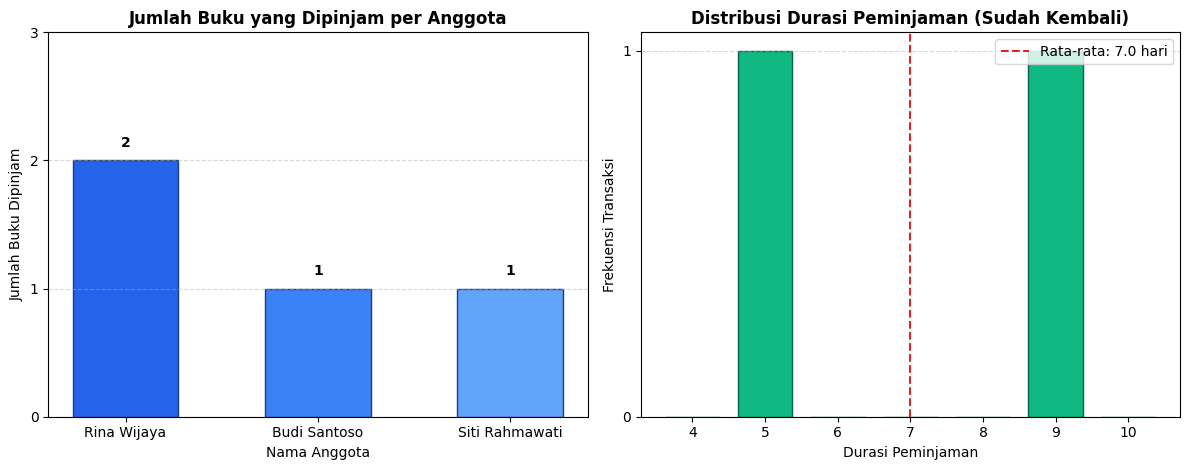

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Grafik 1: Diagram Batang
bars = axes[0].bar(
    df_per_anggota["nama_anggota"],
    df_per_anggota["total_buku_dipinjam"],
    color=["#2563EB", "#3B82F6", "#60A5FA"],
    edgecolor="#1E3A8A",
    width=0.55,
)
axes[0].set_title("Jumlah Buku yang Dipinjam per Anggota", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Nama Anggota")
axes[0].set_ylabel("Jumlah Buku Dipinjam")
axes[0].set_ylim(0, df_per_anggota["total_buku_dipinjam"].max() + 1)
axes[0].yaxis.get_major_locator().set_params(integer=True)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    tinggi = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        tinggi + 0.08,
        f"{int(tinggi)}",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

# Grafik 2: Histogram Distribusi Durasi Peminjaman
axes[1].hist(
    durasi_selesai,
    bins=range(int(durasi_selesai.min()) - 1, int(durasi_selesai.max()) + 3),
    color="#10B981",
    edgecolor="#065F46",
    align="left",
    rwidth=0.75,
)
axes[1].axvline(
    durasi_selesai.mean(),
    color="#DC2626",
    linestyle="--",
    linewidth=1.5,
    label=f"Rata-rata: {durasi_selesai.mean():.1f} hari",
)
axes[1].set_title("Distribusi Durasi Peminjaman (Sudah Kembali)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Durasi Peminjaman")
axes[1].set_ylabel("Frekuensi Transaksi")
axes[1].yaxis.get_major_locator().set_params(integer=True)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

In [10]:
conn.close()
print("Koneksi database ditutup.")

Koneksi database ditutup.
